# F03.07 · Preentrenar la red con EEG sin etiquetas (como Tang) y ajustarla a predecir

![Portada del notebook F03.07](img/portada_notebook_07.png)

> 🧭 **En 30 segundos**
> - **Para qué:** las redes de F03.04-F03.06 se aprenden de memoria a los ~90 pacientes con crisis de 🔵 train y no superan a XGBoost. Aquí la red aprende primero **cómo es un EEG** con **toda** la señal de 🔵 train (también los ~400 pacientes sin crisis, que la predicción no puede usar) y después se **ajusta** a ⏳/💤.
> - **Entra:** los EDF de 🔵 train (se preprocesan aquí, con la misma cadena que F02.02), los paquetes de F03.01, la decisión de F03.03 y las puntuaciones de XGBoost (F03.03) y de la red sin preentrenar (F03.06) → **Sale:** el corpus sin etiquetas, la red preentrenada, la red ajustada, su nota en 🟡 dev y la comparación con y sin preentrenar.
> - **Idea clave:** la tarea sin etiquetas es la de Tang et al. (ICLR 2022): **ver 60 s y predecir los 12 s siguientes**. Para hacerlo bien la red tiene que aprender ritmos, artefactos y cambios de estado. Esa parte de la red (la proyección y la GRU) se copia a la red de predicción.

> 📍 **Dónde estamos: Fase 3 · notebook 7 (F03.07).** Viene de F03.06 (la red como Tang, sin preentrenar: por debajo de XGBoost dentro del paciente y sin aguantar el control de sesión; sus cifras se leen de su configuracion.json en §2). Es el último intento con redes antes de cerrar la Fase 3.

> ⏸️ **Se puede parar y seguir.** El corpus (§3) y el preentrenamiento (§4) guardan su avance: si cortas el kernel, al volver a ejecutar siguen donde lo dejaron.

> 🔄 **Es dinámico.** Lee lo que dejaron F03.01, F03.03 y F03.06: las cifras, el veredicto y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Y el preentrenamiento solo usa 🔵 train: si usara 🟡 dev, aunque sea sin etiquetas, la red habría visto a los pacientes con los que se la mide (fuga).

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Piensa en un médico residente. Antes de aprender a reconocer "este paciente va a tener una crisis" (pocos casos), ha visto **miles de horas de EEG normales**: sabe cómo suena un EEG tranquilo, uno somnoliento, uno con artefactos. Con esa base, aprende la tarea difícil con muchos menos ejemplos. El preentrenamiento hace eso con la red.

| Paso | Qué ve la red | Etiquetas | Qué aprende |
|---|---|---|---|
| **1. Preentrenar** (§4) | ~500 h de EEG de 🔵 train (todos sus pacientes) | ninguna | a **predecir los 12 s siguientes**: cómo evoluciona el EEG |
| **2. Ajustar** (§5) | las ventanas ⏳/💤 de F03.01 | ⏳ / 💤 | a **predecir crisis**, partiendo de lo aprendido en el paso 1 |

![Preentrenar sin etiquetas y después ajustar](img/preentreno_autosupervisado.png)

| Pregunta | Dónde se responde |
|---|---|
| ¿Aprende algo la tarea sin etiquetas (predice mejor que "lo normal del paciente")? | §4 |
| ¿Preentrenar mejora la red de F03.06? ¿Supera ya a XGBoost **dentro del paciente**? | §6 (recuadro dorado) |
| ¿Lo aprendido sirve tal cual (red congelada) o hay que ajustarlo todo? | §6 |
| ¿Aguanta el control de sesión? | §7 |

![La historia de la Fase 3, con F03.07 destacado](img/historia_fase_03_nb07.png)

👀 **Qué enseña.** Las preguntas de toda la fase, en orden, y lo que salió. El recuadro rojo marca **dónde estás**; el resto de la fase sale atenuado.

## El recorrido de este notebook

![El recorrido del notebook F03.07](img/mapa_notebook_07.png)

1. Parámetros, librerías y configuración (§0-§2) · 2. **El corpus sin etiquetas** (§3) · 3. **Preentrenar** (§4) · 4. **Ajustar a ⏳/💤** (§5) · 5. **La nota frente a F03.06 y XGBoost** (§6) · 6. Por paciente, grupo y control de sesión (§7) · 7. Ficheros, resumen y conclusiones (§8-§10).

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Autosupervisado** | Aprender sin etiquetas: la propia señal da la respuesta (aquí, los 12 s que vienen después) |
| **Corpus** | Toda la señal sin etiquetar que se usa para preentrenar |
| **Codificador** | La parte de la red que **lee** la señal (proyección + GRU). Es lo que se reutiliza |
| **Decodificador** | La parte que solo sirve para el preentrenamiento: escribe los 12 s futuros. Se tira al terminar |
| **MAE** | Error absoluto medio: cuánto se equivoca, de media, cada número predicho (Tang usa el mismo) |
| **Suelo** | La pérdida de predecir siempre "lo normal del paciente" (todo 0 tras normalizar). Si la red no lo baja, no ha aprendido nada |
| **Ajuste fino** | Entrenar la red de predicción partiendo de los pesos preentrenados en vez de pesos al azar |
| **Congelar** | No dejar que cambien unos pesos: solo aprende la capa final |

## 0. Los parámetros

> 🎯 **Qué hacemos:** elegir el conjunto, si se hace una prueba rápida y si se reentrena todo.
>
> 🤔 **Por qué:** el registro guarda cada variante: sin `REENTRENAR`, solo se entrena lo que falta.

- `CONJUNTO`: `None` = el de `tfm_comun/prediccion/estudio.py`. Solo afecta al ajuste fino (§5-§7): el preentrenamiento es el mismo para todos los conjuntos (es 🔵 train sin etiquetas).
- `MODO_PRUEBA`: `True` para comprobar que todo funciona en pocos minutos (corpus de 20 pacientes, 2 épocas de preentrenamiento, 10 % de las ventanas en el ajuste). Va a carpetas aparte, `_prueba`.
- `REPREENTRENAR`: `True` borra el preentrenamiento guardado y empieza de cero (el corpus no se toca).
- `REENTRENAR`: `True` vuelve a hacer el ajuste fino aunque esté en el registro.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill.)*

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí
MODO_PRUEBA = False
REPREENTRENAR = False
REENTRENAR = False

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar las librerías (PyTorch con GPU entre ellas) y cargar las de `tfm_comun/red/`.
>
> 🤔 **Por qué:** son las mismas piezas que el resto de redes de la fase: así solo cambia lo que se prueba.

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_RED
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_RED)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características
torch,✅,2.15.0+cu132,"la red neuronal: capas, entrenamiento en la GPU (PyTorch)"


Todo lo necesario está instalado.


In [3]:
# 1) Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# 2) Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado)
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# 3) Librerías de siempre
import gc
import json
from functools import partial
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import mne
import torch
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# 4) tfm_comun: entorno
from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_01, RUTA_OUTPUTS_FASE_03, carpeta_resultados, indice_edf
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.dispositivo import elegir_dispositivo
from tfm_comun.entorno.configuracion import leer_configuracion

# 5) tfm_comun: preentrenamiento autosupervisado (corpus, red, lotes, pesos)
from tfm_comun.red.autosupervisado.corpus_construccion import RUTA_CORPUS, construir_corpus, plan_corpus
from tfm_comun.red.autosupervisado.corpus import Corpus
from tfm_comun.red.autosupervisado.preentrenar import PREENTRENO, preentrenar
from tfm_comun.red.autosupervisado.lotes_corpus import LotesCorpus
from tfm_comun.red.autosupervisado.transferencia_pesos import congelar_codificador, pasar_pesos
from tfm_comun.red.autosupervisado.estadisticos_paciente import estadisticos_por_paciente
from tfm_comun.red.autosupervisado.perdida_futuro import perdida_sin_aprender

# 6) tfm_comun: red, entrenamiento y evaluación
from tfm_comun.red.preparacion import preparar_datos_red
from tfm_comun.red.reproducibilidad import fijar_semillas
from tfm_comun.red.redes.preentreno import RedPreentreno
from tfm_comun.red.redes.gru_segundos import ARQUITECTURA_SEGUNDOS
from tfm_comun.red.modelo import contar_parametros
from tfm_comun.red.entreno.entrenar_red import ENTRENAMIENTO
from tfm_comun.red.experimentos.registro import Registro
from tfm_comun.red.entreno.variantes import EntrenadorVariantes
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente, auroc_dentro_paciente
from tfm_comun.prediccion.control_sesion import controles_de_sesion
from tfm_comun.prediccion.evaluacion.evaluador import Evaluador
from tfm_comun.prediccion.evaluacion.lectura import lectura_diferencia

# 7) tfm_comun: cómo se enseñan las cosas (iconos, colores, números, tablas, ficheros, letra)
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

# 8) Versiones de las librerías
versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, mne, torch)

# 9) El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
mne         1.13.2
torch       2.15.0+cu132


✅ **Qué deberías ver:** en la tabla de librerías, todas con ✅ (o 🆕 si se acaban de instalar), y debajo la versión de cada una.

## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" y leer lo que dejaron F01.01 (la lista de EDF), F03.01, F03.03 y F03.06.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `HORAS_MAX_PACIENTE` | 2 | Tope de señal por paciente en el corpus: unos pocos pacientes tienen más de 30 h y dominarían |
| `AJUSTES_PREENTRENO` | ver abajo | 60 s de contexto (15 ventanas) → 12 s de futuro (3 ventanas); 100.000 secuencias por época; hasta 30 épocas; para si en 5 épocas no mejora la validación |
| `ARQUITECTURA` | `ARQUITECTURA_SEGUNDOS` | La red de F03.06 (proyección + GRU de 2 × 64): así se compara con y sin preentrenar con la MISMA red |
| `N_SEMILLAS` | 3 | El ajuste fino se repite 3 veces (como F03.04-F03.06). El preentrenamiento se hace una vez (es lo caro) |
| `CONTEXTO_S` | 60 | El clip del ajuste fino, como F03.06 |

In [4]:
# 1) El corpus y el preentrenamiento
HORAS_MAX_PACIENTE = 2.0
AJUSTES_PREENTRENO = dict(PREENTRENO)            # tfm_comun/red/autosupervisado/
ARQUITECTURA = dict(ARQUITECTURA_SEGUNDOS)

# 2) Semillas y clip
N_SEMILLAS = 3
CONTEXTO_S = 60

# 3) Cómo se evalúa
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">REPREENTRENAR</code> · <code>True</code> = volver a preentrenar aunque ya esté hecho <i style="color:#4d4d4d">(§0)</i></li></ul></div>

In [5]:
# 1) Carpetas de resultados y modelos, y el registro de experimentos
SUFIJO = '_prueba' if MODO_PRUEBA else ''
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/07_preentreno' + SUFIJO)
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'
RUTA_MODELOS.mkdir(exist_ok=True)
registro = Registro(RUTA_RESULTADOS / 'registro')

# 2) Dónde están el corpus y la red preentrenada (compartidos por todos los conjuntos)
RUTA_CORPUS_USADA = RUTA_CORPUS.with_name(RUTA_CORPUS.name + SUFIJO)            # outputs/fase_03/comun/preentreno/corpus_logfft
RUTA_PREENTRENO = RUTA_CORPUS.parent / ('red_preentrenada' + SUFIJO)             # puntos de control del preentrenamiento

# 3) Modo prueba: 1 semilla y un preentrenamiento corto
if MODO_PRUEBA:
    N_SEMILLAS = 1
    AJUSTES_PREENTRENO.update({'epocas_max': 2, 'muestras_por_epoca': 5_000})

# 4) Semillas
SEMILLAS = [42 + s for s in range(N_SEMILLAS)]

# 5) leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_03 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'configuracion.json', 'F03.03 (fase_03/03_contexto_y_paciente.ipynb)')
config_06 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('06_red_tang' + SUFIJO) / 'configuracion.json', 'F03.06', obligatorio=False)

# 6) Nombres de los modelos con los que se compara y normalización
NOMBRE_XGB = f'XGBoost F03.03 ({config_03["mejor"]["contexto_s"]} s, {config_03["mejor"]["normalizacion"]})'
NOMBRE_06 = 'red F03.06 sin preentrenar' + (f' ({config_06["principal"]["variante"]})' if config_06 else '')
NORMALIZACION_USADA = config_03['decision_red']['normalizacion']

# 7) REPREENTRENAR: borrar el preentrenamiento anterior para empezar de cero
if REPREENTRENAR and RUTA_PREENTRENO.exists():
    shutil.rmtree(RUTA_PREENTRENO)

# 8) Dónde se entrena (GPU o procesador)
dispositivo, ficha = elegir_dispositivo()

# 9) Resumen
print(f'Conjunto (ajuste fino): {CONJUNTO}{" · 🔴 MODO PRUEBA (cifras sin valor)" if MODO_PRUEBA else ""} · semillas: {SEMILLAS}')
print(f'Corpus: {RUTA_CORPUS_USADA} · preentrenamiento: {RUTA_PREENTRENO}' + (' (empieza de cero)' if REPREENTRENAR else ''))
print(f'Dispositivo: {ficha["dispositivo"]} · {ficha["nombre"]}' + (f' · {ficha["memoria (GB)"]} GB' if ficha['memoria (GB)'] else ''))
print(f'A superar en 🟡 dev: {NOMBRE_XGB} → AUC {decimal(config_03["mejor"]["auc_dev"])}'
      + (f' · {NOMBRE_06} → dentro del paciente {decimal(config_06["principal"]["auc_dentro_paciente_dev"])}' if config_06 else
         ' · (F03.06 no está ejecutado con este conjunto: no se compara con la red sin preentrenar)'))

Conjunto (ajuste fino): general · semillas: [42, 43, 44]
Corpus: D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_03\comun\preentreno\corpus_logfft · preentrenamiento: D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_03\comun\preentreno\red_preentrenada
Dispositivo: cuda (GPU NVIDIA) · NVIDIA GeForce RTX 3060 · 12.9 GB
A superar en 🟡 dev: XGBoost F03.03 (16 s, por_paciente_calibrado) → AUC 0,63 · red F03.06 sin preentrenar (gru_segundos_60s) → dentro del paciente 0,60


## 3. El corpus sin etiquetas

> 🎯 **Qué hacemos:** decidir qué EEG entra (`plan_corpus`) y convertirlo en la entrada de la red (`construir_corpus`, `tfm_comun/red/autosupervisado/`): cada EDF de 🔵 train se lee, pasa por la **misma cadena que F02.02** (montaje TCP, 256 Hz, filtro 0,5-40 Hz) y se convierte en la **misma log-FFT por segundo que F03.06**, en ventanas de 4 s seguidas.
>
> 🤔 **Reglas:** solo 🔵 train; como mucho 2 h por paciente (en el orden de sus ficheros); sin los 10 primeros segundos de cada fichero (arranque del filtro). Los EDF que fallen se apuntan y se saltan.

> 💡 La primera vez tarda (lee unas 500 h de EDF: del orden de **30-60 minutos**). Se puede cortar: al volver, solo hace los ficheros que faltan. Ocupa unos 3 GB.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">HORAS_MAX_PACIENTE</code> · horas de EEG como mucho por paciente en el corpus <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_CORPUS_USADA</code> · carpeta del corpus sin etiquetar <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [6]:
# 1) El inventario de F01 (EDF y crisis)
edfs = pd.read_csv(RUTA_OUTPUTS_FASE_01 / '01_inventario' / 'edfs.csv')
crisis = pd.read_csv(RUTA_OUTPUTS_FASE_01 / '01_inventario' / 'crisis.csv')

# 2) El plan: qué pacientes y cuántas horas de 🔵 train entran
plan = plan_corpus(edfs, HORAS_MAX_PACIENTE)
if MODO_PRUEBA:
    plan = plan[plan.patient.isin(sorted(plan.patient.unique())[:20])]

# 3) ¿Pacientes con o sin crisis?
con_crisis = set(crisis.loc[crisis.split == 'train', 'patient'])
plan['pacientes'] = np.where(plan.patient.isin(con_crisis), 'con crisis', 'sin crisis')

# 4) Resumen del plan
resumen_plan = plan.groupby('pacientes').agg(pacientes=('patient', 'nunique'), ficheros=('file', 'size'),
                                             horas=('segundos', lambda s: s.sum() / 3600))
resumen_plan.loc['total'] = [plan.patient.nunique(), len(plan), plan.segundos.sum() / 3600]
display(Markdown('**El plan** (🔵 train): qué pacientes y cuántas horas entran'))
display(con_separadores(resumen_plan, decimales=1))

# 5) Construir el corpus (solo lo que falte)
inicio = time.time()
edf_de = indice_edf()
tabla_corpus = construir_corpus(plan.drop(columns='pacientes'), edf_de, ruta=RUTA_CORPUS_USADA,
                                progreso=lambda it, total: tqdm(it, total=total, desc='EDF de 🔵 train'))

# 6) Resumen y errores
errores = tabla_corpus[tabla_corpus.estado != 'hecho']
print(f'Corpus: {numero_legible(int((tabla_corpus.estado == "hecho").sum()))} ficheros hechos · {numero_legible(len(errores))} con error · '
      f'{numero_legible(round(tabla_corpus.ventanas.sum() * 4 / 3600, 1))} h · {numero_legible(round((time.time() - inicio) / 60, 1))} min en esta ejecución')
mostrar_fichero(RUTA_CORPUS_USADA / 'corpus.csv', 'una fila por EDF de 🔵 train: paciente, segundos leídos, ventanas de 4 s guardadas y si ha ido bien')
if len(errores):
    display(errores.head(10))

**El plan** (🔵 train): qué pacientes y cuántas horas entran

,pacientes,ficheros,horas
pacientes,,,
con crisis,"171,0","1.435,0","222,5"
sin crisis,"408,0","1.416,0","267,9"
total,"579,0","2.851,0","490,4"


EDF de 🔵 train:   0%|          | 0/2851 [00:00<?, ?it/s]

Corpus: 2.851 ficheros hechos · 0 con error · 481 h · 11,3 min en esta ejecución


💾 **Guardado `corpus.csv`** · 188,6 KB · 2.851 filas × 6 columnas  
*Qué guarda:* una fila por EDF de 🔵 train: paciente, segundos leídos, ventanas de 4 s guardadas y si ha ido bien. *Abajo:* las 5 primeras filas.

,patient,file,segundos,ventanas,estado,minutos
0,aaaaaaac,aaaaaaac_s001_t000,301.0,72,hecho,0.003620
1,aaaaaaac,aaaaaaac_s001_t001,236.0,56,hecho,0.001252
2,aaaaaaac,aaaaaaac_s002_t000,262.0,63,hecho,0.001485
3,aaaaaaac,aaaaaaac_s004_t000,321.0,77,hecho,0.001614
4,aaaaaaac,aaaaaaac_s004_t002,626.0,154,hecho,0.003279


👀 **Cómo leer las tablas.** Arriba, el plan: cuántos pacientes y horas **con crisis** (los que ya usaba la predicción) y **sin crisis** (los que la predicción no puede usar y aquí sí entran). Abajo, `corpus.csv`: una fila por fichero.

✅ **Qué deberías ver:** unas 400-500 h, más de la mitad de pacientes **sin crisis**, y pocos o ningún fichero con error.

## 4. Preentrenar: ver 60 s y predecir los 12 s siguientes

> 🎯 **Qué hacemos:** cargar el corpus, separar un 10 % de sus **pacientes** para vigilar la tarea (validación del preentrenamiento, siempre de 🔵 train), normalizar cada paciente frente a sí mismo y entrenar `RedPreentreno` (`tfm_comun/red/redes/preentreno.py`): el codificador de F03.06 + un decodificador que escribe los 12 s siguientes. Pérdida: error absoluto medio (MAE), como Tang.
>
> 🤔 **El suelo:** antes de entrenar se mide la pérdida de predecir siempre "lo normal del paciente" (todo 0 tras normalizar). Si la red no baja de ahí, no ha aprendido nada de cómo evoluciona el EEG.

> 💡 Cada época son 100.000 secuencias. Con GPU, del orden de **1-3 minutos por época**. Se guarda un punto de control al final de cada época: si cortas, al volver sigue en la siguiente.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AJUSTES_PREENTRENO</code> · ajustes del preentrenamiento (épocas, lote...) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_CORPUS_USADA</code> · carpeta del corpus sin etiquetar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [7]:
# 1) Cargar el corpus
inicio = time.time()
corpus = Corpus(RUTA_CORPUS_USADA)

# 2) Pacientes aparte para vigilar el preentrenamiento
pacientes_corpus = np.array(sorted(set(corpus.paciente)))
rng = np.random.default_rng(42)
pacientes_valida = set(rng.choice(pacientes_corpus, max(1, int(round(AJUSTES_PREENTRENO['fraccion_validacion'] * len(pacientes_corpus)))), replace=False))

# 3) Las secuencias: contexto + futuro que se predice
K_CONTEXTO, K_FUTURO = AJUSTES_PREENTRENO['ventanas_contexto'], AJUSTES_PREENTRENO['ventanas_futuro']
inicios = corpus.inicios_validos(K_CONTEXTO + K_FUTURO)
es_valida = np.isin(corpus.paciente[inicios], list(pacientes_valida))
inicios_entrena, inicios_valida = inicios[~es_valida], inicios[es_valida]

# 4) Normalización por paciente y lotes
indice_paciente, medianas, escalas = estadisticos_por_paciente(corpus.valores, corpus.paciente, AJUSTES_PREENTRENO['ventanas_estadisticos'])
lotes = LotesCorpus(corpus, indice_paciente, medianas, escalas, dispositivo, K_CONTEXTO, K_FUTURO)

# 5) El suelo: el error sin aprender nada
muestra_suelo = np.random.default_rng(42).choice(inicios_valida, min(20_000, len(inicios_valida)), replace=False)
SUELO = perdida_sin_aprender(lotes, muestra_suelo)

# 6) Tabla del corpus
tabla_corpus_cargado = pd.DataFrame({'horas': [corpus.horas], 'ventanas de 4 s': [len(corpus.valores)], 'pacientes': [len(pacientes_corpus)],
                                     'pacientes para vigilar': [len(pacientes_valida)], 'secuencias de entrenamiento': [len(inicios_entrena)],
                                     'secuencias de validación': [len(inicios_valida)], 'GB (float16)': [corpus.valores.nbytes / 1e9],
                                     'en': ['GPU' if lotes.en_gpu else 'memoria'], 'suelo (MAE)': [SUELO],
                                     'minutos': [(time.time() - inicio) / 60]}, index=['corpus'])
display(con_separadores(tabla_corpus_cargado, decimales=2))

,horas,ventanas de 4 s,pacientes,pacientes para vigilar,secuencias de entrenamiento,secuencias de validación,GB (float16),en,suelo (MAE),minutos
corpus,"480,98",432.883,579,58,345.313,40.561,"3,05",GPU,"0,84","3,60"


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AJUSTES_PREENTRENO</code> · ajustes del preentrenamiento (épocas, lote...) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ARQUITECTURA</code> · tamaños de la red (capas, unidades, dropout) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_PREENTRENO</code> · carpeta con los puntos de control del preentrenamiento <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [8]:
# 1) La red de preentrenamiento
fijar_semillas(42)
red_preentreno = RedPreentreno(22, corpus.valores.shape[1] // 22, ARQUITECTURA, segundos_futuro=K_FUTURO * 4).to(dispositivo)

# 2) Sus parámetros
display(con_separadores(pd.DataFrame([{**{f'codificador · {k}': v for k, v in contar_parametros(red_preentreno.red).items() if k != 'final'},
                                       'decodificador': sum(p.numel() for p in red_preentreno.decodificador.parameters()),
                                       'salida': sum(p.numel() for p in red_preentreno.salida.parameters())}], index=['parámetros']), decimales=0))

# 3) Preentrenar (o seguir donde se quedó)
inicio = time.time()
historial_pre, mejor_pre = preentrenar(red_preentreno, lotes, inicios_entrena, inicios_valida, RUTA_PREENTRENO, ajustes=AJUSTES_PREENTRENO,
                                       progreso=lambda it, initial, total: tqdm(it, initial=initial, total=total, desc='épocas de preentrenamiento'))
display(con_separadores(historial_pre.set_index('época'), decimales=4))

# 4) ¿Cuánto baja del suelo?
mejora_suelo = 1 - mejor_pre['perdida_validacion'] / SUELO
print(f'Mejor época: {mejor_pre["epoca"]} · MAE en validación {decimal(mejor_pre["perdida_validacion"], 4)} frente al suelo {decimal(SUELO, 4)} '
      f'({decimal(100 * mejora_suelo, 1)} % menos) · {numero_legible(round((time.time() - inicio) / 60, 1))} min en esta ejecución')
print('✅ Ha aprendido algo de cómo evoluciona el EEG' if mejora_suelo > 0.02 else
      '🔴 Casi no baja del suelo: el preentrenamiento no ha aprendido; el ajuste fino partirá de algo parecido a pesos al azar')

,codificador · proyeccion,codificador · gru,codificador · total,decodificador,salida
parámetros,56.512,49.920,106.497,49.920,57.200


épocas de preentrenamiento:   0%|          | 0/30 [00:00<?, ?it/s]

,pérdida train,pérdida validación,tasa de aprendizaje,minutos
época,,,,
1,"0,8129","0,8059","0,0010","0,0928"
2,"0,8075","0,8050","0,0010","0,0662"
3,"0,8063","0,8037","0,0010","0,0638"
4,"0,8052","0,8033","0,0010","0,0636"
5,"0,8044","0,8029","0,0010","0,0728"
6,"0,8043","0,8024","0,0010","0,0657"
7,"0,8038","0,8021","0,0010","0,0685"
8,"0,8036","0,8021","0,0010","0,0665"
9,"0,8035","0,8016","0,0010","0,0695"


Mejor época: 21 · MAE en validación 0,8004 frente al suelo 0,8361 (4,3 % menos) · 1,8 min en esta ejecución
✅ Ha aprendido algo de cómo evoluciona el EEG


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li></ul></div>

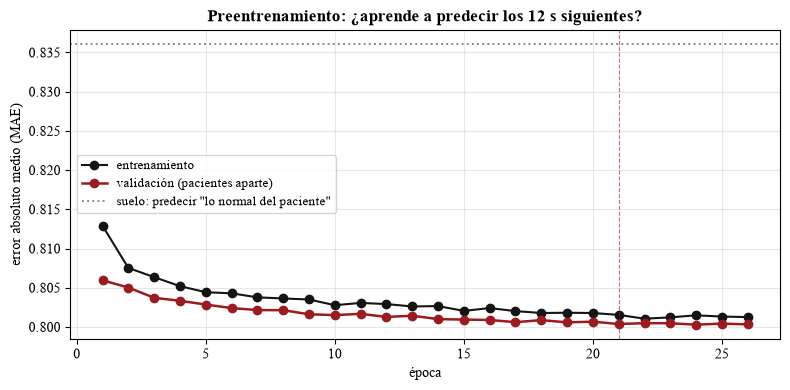

In [9]:
# 1) Curvas de pérdida, el suelo y la mejor época
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(historial_pre['época'], historial_pre['pérdida train'], color=COLORES_ESQUEMA['negro'], marker='o', lw=1.5, label='entrenamiento')
    ax.plot(historial_pre['época'], historial_pre['pérdida validación'], color=COLORES_ESQUEMA['rojo'], marker='o', lw=1.8, label='validación (pacientes aparte)')
    ax.axhline(SUELO, color=COLORES_ESQUEMA['gris'], ls=':', lw=1.4, label='suelo: predecir "lo normal del paciente"')
    ax.axvline(mejor_pre['epoca'], color=COLORES_ESQUEMA['rojo'], ls='--', lw=0.8, alpha=0.6)

    # 2) Rotular
    ax.set_xlabel('época')
    ax.set_ylabel('error absoluto medio (MAE)')
    ax.set_title('Preentrenamiento: ¿aprende a predecir los 12 s siguientes?', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

    # 3) Guardar
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'preentrenamiento.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la tabla y la figura.** El error de predecir los 12 s siguientes, época a época: en entrenamiento (negro) y en los pacientes que se dejaron aparte (rojo). La línea gris de puntos es el **suelo**. La línea discontinua roja marca la época que se guarda.

✅ **Qué deberías ver:** la curva roja **claramente por debajo del suelo** y bajando las primeras épocas. Si se queda pegada al suelo, la red no ha aprendido la tarea y el ajuste fino no ganará nada.

## 5. Ajustar a ⏳/💤

> 🎯 **Qué hacemos:** liberar la memoria del corpus, preparar **exactamente los datos de F03.06** (mismas filas, misma log-FFT, misma normalización: `preparar_datos_red`) y entrenar dos redes que parten del preentrenamiento:
>
> - **`preentrenada`**: se copian la proyección y la GRU preentrenadas y se ajusta **toda** la red (como Tang).
> - **`preentrenada_congelada`**: lo preentrenado queda **fijo** y solo aprende la capa final. Responde a "¿lo aprendido sin etiquetas ya separa ⏳ de 💤 por sí solo?".
>
> Se entrenan igual que la red de F03.06 (mismos ajustes), para que la única diferencia sea el punto de partida.

> 🧱 **Cómo está hecho el código.** Cada variante se entrena con `EntrenadorVariantes` (`tfm_comun/red/entreno/variantes.py`), igual que en F03.06. Lo único propio de este notebook es `preparar_red`: lo que se hace con cada red recién creada **antes** de entrenar (copiar el codificador preentrenado con `pasar_pesos` y, en la variante congelada, `congelar_codificador`). Las piezas del preentrenamiento están en `tfm_comun/red/autosupervisado/` (una por fichero: corpus, lotes, pérdida, bucle y transferencia de pesos).


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code> · segundos de contexto que ve la red (F03.03) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUFIJO</code> · <code>_prueba</code> en los ficheros si es una prueba <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_01</code> · configuración de F03.01 (semilla, ventanas) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_03</code> · configuración de F03.03 (la decisión para la red) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_06</code> · configuración de F03.06 (la red como Tang) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">corpus</code> · el corpus de EEG sin etiquetar (solo 🔵 train) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">lotes</code> · sirve lotes del corpus: contexto y futuro <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">red_preentreno</code> · la red que aprende a predecir el EEG que viene <i style="color:#4d4d4d">(§4)</i></li></ul></div>

In [10]:
# 1) Liberar la memoria del corpus
del lotes, corpus
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 2) Los datos del ajuste fino (los mismos que F03.06)
inicio = time.time()
red_datos = preparar_datos_red(CONJUNTO, config_01, config_03, dispositivo, modo_prueba=MODO_PRUEBA,
                               progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'),
                               entrada='log_fft_segundo', contexto_s=CONTEXTO_S)
filas, y, pacientes, rondas, validar, datos = (red_datos.filas, red_datos.y, red_datos.pacientes, red_datos.rondas,
                                               red_datos.validar, red_datos.datos)
FS, K = red_datos.fs, red_datos.k
ids_validacion = filas.id_ventana.to_numpy()[validar]

# 3) La entrada del ajuste fino tiene que ser la del preentrenamiento
assert red_datos.n_frecuencias * 22 == red_preentreno.red.n_canales * red_preentreno.red.segundos * red_preentreno.red.frecuencias, \
    'La entrada del ajuste fino no es la misma que la del preentrenamiento.'

# 4) Las puntuaciones de XGBoost (F03.03) en las mismas ventanas
puntos_03 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'puntuaciones_validacion.csv').set_index('id_ventana')
comun = validar & filas.id_ventana.isin(puntos_03.index).to_numpy()
p_xgb = np.full(len(filas), np.nan)
p_xgb[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_mejor'].to_numpy()

# 5) Las de la red sin preentrenar (F03.06), si está ejecutada
p_06 = None
if config_06:
    puntos_06 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('06_red_tang' + SUFIJO) / 'puntuaciones_validacion.csv').set_index('id_ventana')
    columna_06 = f'puntuacion_{config_06["principal"]["variante"]}'
    if columna_06 in puntos_06 and filas.id_ventana[comun].isin(puntos_06.index).all():
        p_06 = np.full(len(filas), np.nan)
        p_06[comun] = puntos_06.loc[filas.id_ventana[comun], columna_06].to_numpy()

# 6) Tabla de los datos
tabla_datos = pd.DataFrame({'filas': [len(filas)], 'entrenamiento': [int(filas.en_entrenamiento.sum())], 'validación': [int(validar.sum())],
                            'pacientes': [len(set(pacientes))], 'segundos por clip': [K * 4], 'entrada': [red_datos.estado_almacen],
                            'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_datos.index.name = 'conjunto'
display(con_separadores(tabla_datos, decimales=1))

# 7) Resumen
print(f'Ventanas de 🟡 dev comparadas: {numero_legible(int(comun.sum()))} de {numero_legible(int(validar.sum()))}'
      + (' (✅ todas)' if comun.sum() == validar.sum() else ' (🔴 faltan: vuelve a ejecutar F03.03)'))
print('Red sin preentrenar (F03.06): ' + ('✅ mismas ventanas, se compara en §6' if p_06 is not None else '— no se compara (ejecuta antes F03.06)'))

,filas,entrenamiento,validación,pacientes,segundos por clip,entrada,minutos
conjunto,,,,,,,
general,78.242,27.074,51.168,129,60,ya estaba al día,"2,0"


Ventanas de 🟡 dev comparadas: 51.168 de 51.168 (✅ todas)
Red sin preentrenar (F03.06): ✅ mismas ventanas, se compara en §6


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">REENTRENAR</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AJUSTES_PREENTRENO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ARQUITECTURA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESPECIFICIDAD</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">HORAS_MAX_PACIENTE</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION_USADA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_MODELOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">registro</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor_pre</code></li></ul></div>

In [ ]:
# 1) El ajuste fino: los mismos ajustes que F03.06
ENTRENAMIENTO_AJUSTE = {**ENTRENAMIENTO, 'evaluaciones_por_epoca': 4, 'lr': 3e-4, 'equilibrar_clases': True, 'epocas_max': 60,
                        'tapar_frecuencias': 0, 'criterio': 'auc_dentro_paciente'}      # los mismos que F03.06
if MODO_PRUEBA:
    ENTRENAMIENTO_AJUSTE['epocas_max'] = 2

# 2) Lo que identifica al preentrenamiento
ID_PREENTRENO = {'ajustes': AJUSTES_PREENTRENO, 'arquitectura': ARQUITECTURA, 'horas_max_paciente': HORAS_MAX_PACIENTE,
                 'mejor_epoca': int(mejor_pre['epoca']), 'perdida': round(float(mejor_pre['perdida_validacion']), 6)}

# 3) Las dos variantes: ajustar toda la red o solo la capa final
VARIANTES = {
    'preentrenada': {'congelar': False, 'entrenamiento': dict(ENTRENAMIENTO_AJUSTE),
                     'qué es': 'parte del preentrenamiento y se ajusta toda la red (como Tang)'},
    'preentrenada_congelada': {'congelar': True, 'entrenamiento': {**ENTRENAMIENTO_AJUSTE, 'lr': 1e-3},
                               'qué es': 'lo preentrenado queda fijo; solo aprende la capa final'},
}
PRINCIPAL = 'preentrenada'

# 4) Las notas de cada modelo, siempre con las mismas ventanas de 🟡 dev (comun) y los mismos sorteos de pacientes
evaluador = Evaluador(y, pacientes, comun, especificidad=ESPECIFICIDAD, n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])

# 5) Entrenar (o leer del registro) cada variante: tfm_comun/red/entreno/variantes.py
entrenador = EntrenadorVariantes(red_datos, dispositivo, registro, RUTA_MODELOS, SEMILLAS, CONJUNTO, MODO_PRUEBA,
                                 notebook='F03.07', reentrenar=REENTRENAR, carpeta_puntos_control=RUTA_RESULTADOS / 'puntos_control',
                                 barra=lambda iterable, texto: tqdm(iterable, desc=texto, leave=False))

# 6) La configuración de una variante
def config_de(variante):
    """La configuración completa de una variante: lo que la identifica en el registro (su huella)."""
    return {'arquitectura': ARQUITECTURA, 'entrenamiento': variante['entrenamiento'], 'congelar': variante['congelar'], 'k': K,
            'separacion_s': 16, 'entrada': 'log_fft_segundo', 'normalizacion': NORMALIZACION_USADA, 'preentreno': ID_PREENTRENO}

➡️ **Paso 2.** Se define `preparar_desde_preentreno`.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_PREENTRENO</code> · carpeta con los puntos de control del preentrenamiento <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code> · semillas con las que se entrena cada variante <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">registro</code> · registro de experimentos: lo ya entrenado no se repite <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [ ]:
# 1) Preparar cada red: copiar lo preentrenado y, si se pide, congelarlo
def preparar_desde_preentreno(congelar):
    """Lo que se hace con cada red recién creada: copiar el codificador preentrenado (§4) y, si se pide, congelarlo."""
    def preparar(red):
        pasar_pesos(RUTA_PREENTRENO / 'mejor.pt', red, dispositivo)
        if congelar:
            congelar_codificador(red)
    return preparar

# 2) Entrenar (o leer) y evaluar cada variante
puntuaciones, historiales, resultados = {}, {}, []
for nombre, variante in VARIANTES.items():
    config = config_de(variante)
    h, P, historial, estado, minutos = entrenador.entrenar(nombre, config, preparar_red=preparar_desde_preentreno(variante['congelar']))
    p = np.full(len(filas), np.nan)
    p[validar] = P[:, validar].mean(axis=0)
    notas = evaluador.notas(p)
    puntuaciones[nombre], historiales[nombre] = p, historial
    columna = 'AUC dentro paciente' if 'AUC dentro paciente' in historial else 'AUC validación'
    mejores_epocas = historial.loc[historial.groupby(['semilla', 'ronda'])[columna].idxmax(), 'época']

    # 3) Su fila de la tabla
    resultados.append({'variante': nombre, 'qué es': variante['qué es'], **notas,
                       'AUC dentro del paciente de cada semilla': ' · '.join(decimal(auroc_dentro_paciente(y[comun], f[comun], pacientes[comun])) for f in P),
                       'mejor época (media)': float(mejores_epocas.mean()), 'huella': h, 'estado': estado, 'minutos': minutos})

    # 4) Guardarla en el registro
    registro.guardar(h, {'nombre': nombre, 'fecha': time.strftime('%Y-%m-%d %H:%M'), 'conjunto': CONJUNTO, 'auc_dev': notas['AUC-ROC'],
                         'auc_dentro_paciente': notas['AUC dentro del paciente'], 'semillas': len(SEMILLAS),
                         'configuracion': json.dumps(config, ensure_ascii=False)}, P[:, validar], ids_validacion, historial)

# 5) Tabla de resultados
resultados = pd.DataFrame(resultados).set_index('variante')
columnas_ver = ['qué es', 'AUC dentro del paciente', 'AUC-ROC', 'AUC dentro del paciente de cada semilla', 'AUC por paciente (mediana)',
                'sensibilidad (esp. 90 %)', 'mejor época (media)', 'estado', 'minutos']
display(con_separadores(resultados[columnas_ver], decimales=3))

👀 **Cómo leer la tabla.** Una fila por variante: las dos notas en 🟡 dev (media de las semillas), la nota dentro del paciente de cada semilla, la mediana por paciente, la sensibilidad con especificidad del 90 % y la **mejor época**. Si la mejor época sube respecto a la de F03.06 (la columna *mejor época (media)* de su `resultados_dev.csv`), la red tarda más en memorizar: buena señal.

✅ **Qué deberías ver:** la preentrenada y la de F03.06 con notas parecidas si preentrenar no ayuda; si ayuda, la preentrenada por encima y con una mejor época más tardía.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li></ul></div>

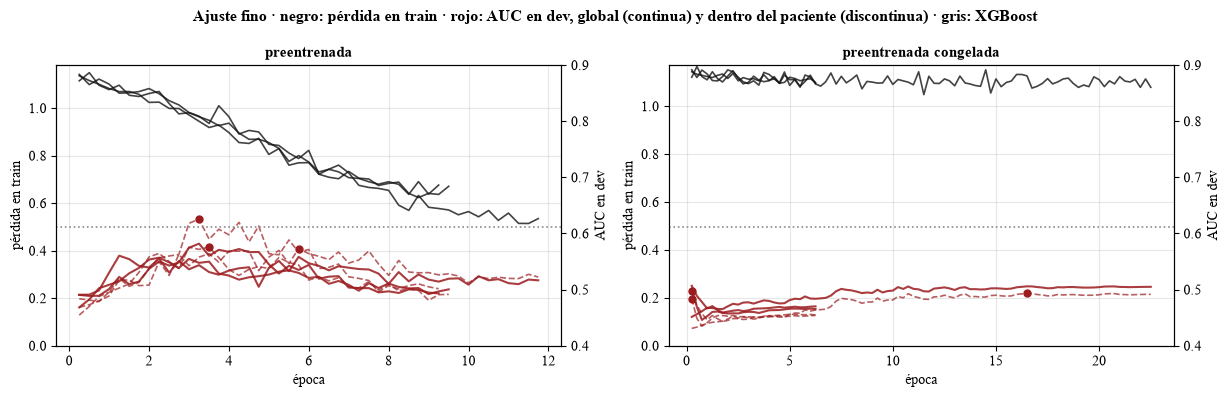

In [12]:
# 1) Un panel por variante: pérdida (negro) y AUC (rojo) de cada semilla y ronda
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(historiales), figsize=(6.2 * len(historiales), 4), squeeze=False)
    for ax, (nombre, h) in zip(axes.flat, historiales.items()):
        ax2 = ax.twinx()
        for _, hs in h.groupby(['semilla', 'ronda']):
            ax.plot(hs['época'], hs['pérdida train'], color=COLORES_ESQUEMA['negro'], lw=1.2, alpha=0.8)
            ax2.plot(hs['época'], hs['AUC validación'], color=COLORES_ESQUEMA['rojo'], lw=1.5, alpha=0.85)
            if 'AUC dentro paciente' in hs and hs['AUC dentro paciente'].notna().any():
                ax2.plot(hs['época'], hs['AUC dentro paciente'], color=COLORES_ESQUEMA['rojo'], lw=1.2, ls='--', alpha=0.7)
                m = hs.loc[hs['AUC dentro paciente'].idxmax()]
                ax2.plot(m['época'], m['AUC dentro paciente'], 'o', color=COLORES_ESQUEMA['rojo'], ms=5)

        # 2) La nota de XGBoost dentro del paciente (línea gris)
        ax2.axhline(auroc_dentro_paciente(y[comun], p_xgb[comun], pacientes[comun]), color=COLORES_ESQUEMA['gris'], ls=':', lw=1.2)

        # 3) Rotular
        ax.set_title(nombre.replace('_', ' '), fontsize=11, fontweight='bold')
        ax.set_xlabel('época')
        ax.set_ylabel('pérdida en train')
        ax2.set_ylabel('AUC en dev')
        ax.grid(alpha=0.3)
        ax.set_ylim(bottom=0)
        ax2.set_ylim(0.4, 0.9)

    # 4) Título y guardar
    fig.suptitle('Ajuste fino · negro: pérdida en train · rojo: AUC en dev, global (continua) y dentro del paciente (discontinua) · gris: XGBoost',
                 fontsize=11.5, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_ajuste_fino.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Como en F03.06: negro, la pérdida en train; rojo, la AUC en 🟡 dev (continua, global; discontinua, dentro del paciente, con un punto en la época que se guarda); gris, XGBoost dentro del paciente.

✅ **Qué deberías ver:** con el preentrenamiento, la AUC de dev **arrancando más alta** que en F03.06 (la red ya sabe leer EEG) y aguantando más épocas antes de caer.

## 6. ¿Ha servido preentrenar? La nota frente a F03.06 y XGBoost

> 🎯 **Qué hacemos:** comparar, con las mismas ventanas de 🟡 dev, la red preentrenada con **la misma red sin preentrenar** (F03.06), con XGBoost y con su versión congelada. Diferencias **emparejadas** con su intervalo del 95 %.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code> · mejora mínima de AUC para dar por buena una mejora <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_06</code> · nombre de la red de F03.06 sin preentrenar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code> · nombre de la variante principal de la red <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">evaluador</code> · calcula todas las notas con las mismas ventanas <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_06</code> · puntuación de la red de F03.06 en cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · puntuación de cada ventana de dev, por variante <i style="color:#4d4d4d">(§5)</i></li></ul></div>

In [ ]:
# 1) Las notas de la red preentrenada y de XGBoost
p_red = puntuaciones[PRINCIPAL]
notas_red, notas_xgb = evaluador.notas(p_red), evaluador.notas(p_xgb)

# 2) ¿Mejora a la red sin preentrenar (F03.06)?
comparaciones = []
d_06 = None
if p_06 is not None:
    d_06 = evaluador.diferencia(p_red, p_06)
    comparaciones.append(('¿preentrenar mejora la red de F03.06? (dentro del paciente)', NOMBRE_06, d_06))

# 3) Frente a XGBoost y frente a congelar
d_xgb_dentro, d_xgb_global = evaluador.diferencia(p_red, p_xgb), evaluador.diferencia(p_red, p_xgb, dentro=False)
d_congelada = evaluador.diferencia(p_red, puntuaciones['preentrenada_congelada'])
comparaciones += [('¿supera a XGBoost DENTRO del paciente?', NOMBRE_XGB, d_xgb_dentro),
                  ('¿supera a XGBoost en la nota GLOBAL?', NOMBRE_XGB, d_xgb_global),
                  ('¿ajustar todo mejora a congelar lo preentrenado? (dentro)', 'preentrenada_congelada', d_congelada)]

# 4) Tabla de comparaciones
comparacion = pd.DataFrame([{'pregunta': q, 'A': PRINCIPAL, 'B': b, 'diferencia (A − B)': con_signo(d[0]),
                             'IC 95 %': f'{decimal(d[1], 3)} – {decimal(d[2], 3)}', 'lectura': lectura_diferencia(d, MEJORA_MINIMA)} for q, b, d in comparaciones]).set_index('pregunta')

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code> · mejora mínima de AUC para dar por buena una mejora <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_06</code> · nombre de la red de F03.06 sin preentrenar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUELO</code> · pérdida de no aprender nada (predecir la media) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">evaluador</code> · calcula todas las notas con las mismas ventanas <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor_pre</code> · la mejor época del preentrenamiento <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejora_suelo</code> · cuánto mejora el preentrenamiento sobre ese suelo <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_06</code> · puntuación de la red de F03.06 en cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · puntuación de cada ventana de dev, por variante <i style="color:#4d4d4d">(§5)</i></li></ul></div>

In [ ]:
# 1) El veredicto
if d_xgb_dentro[1] > 0 and d_xgb_dentro[0] >= MEJORA_MINIMA:
    veredicto = ('✅ La red preentrenada supera a XGBoost dentro del paciente', 'la red preentrenada pasa a ser el modelo de referencia de la fase')
elif d_06 is not None and d_06[1] > 0:
    veredicto = ('🟡 Preentrenar mejora la red, pero no supera a XGBoost', 'el preentrenamiento ayuda (se confirma la idea de Tang en predicción), '
                 'pero XGBoost sigue siendo la referencia')
elif d_xgb_dentro[2] < 0:
    veredicto = ('🔴 La red preentrenada sigue por debajo de XGBoost', 'con estos datos, preentrenar no basta: XGBoost queda como modelo de predicción')
else:
    veredicto = ('🟡 Sin diferencia clara con XGBoost dentro del paciente', f'la red queda {"por encima" if d_xgb_dentro[0] > 0 else "por debajo"} '
                 f'({con_signo(d_xgb_dentro[0])}), pero el intervalo incluye el 0')
if MODO_PRUEBA:
    veredicto = ('🔴 MODO PRUEBA · ' + veredicto[0], veredicto[1] + ' (cifras sin valor)')

# 2) Las dos notas de cada modelo
filas_notas = {'red preentrenada (ajuste completo)': notas_red, 'red preentrenada congelada': evaluador.notas(puntuaciones['preentrenada_congelada'])}
if p_06 is not None:
    filas_notas[NOMBRE_06] = evaluador.notas(p_06)
filas_notas[NOMBRE_XGB] = notas_xgb

# 3) Tabla de notas
tabla_notas = pd.DataFrame({
    'dentro del paciente': [con_intervalo(n['AUC dentro del paciente'], n['_inferior_dentro'], n['_superior_dentro']) for n in filas_notas.values()],
    'global': [con_intervalo(n['AUC-ROC'], n['_inferior'], n['_superior']) for n in filas_notas.values()]},
    index=pd.Index(list(filas_notas), name='AUC en 🟡 dev'))

# 4) Mostrarlo destacado
mostrar_destacado(veredicto[0], 'Las dos notas de cada modelo, con las mismas ventanas de 🟡 dev:', tabla_notas, comparacion,
                  f'<b>Preentrenamiento:</b> MAE {decimal(mejor_pre["perdida_validacion"], 3)} frente al suelo {decimal(SUELO, 3)} '
                  f'({decimal(100 * mejora_suelo, 1)} % menos). <b>Qué significa:</b> {veredicto[1]}.')

👀 **Cómo leer el recuadro.** Arriba, el veredicto. La primera tabla da las dos notas de cada modelo; la segunda, las diferencias emparejadas. **La pregunta principal es la primera**: ¿la misma red, con el preentrenamiento, mejora a la de F03.06? Si el intervalo no incluye el 0, la mejora es real con estos pacientes.

✅ **Qué deberías ver:** si el preentrenamiento funciona, la red preentrenada por encima de la de F03.06 y la congelada al menos por encima del azar (0,5).

## 7. Por paciente, por grupo de inicio y control de sesión

> 🎯 **Qué hacemos:** mirar la red preentrenada por paciente, por grupo de inicio y en el control de sesión.
>
> 🤔 **Por qué:** una mejora global puede esconder pacientes que empeoran, o apoyarse en la grabación.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_06</code> · puntuación de la red de F03.06 en cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_red</code> · puntuación de la red (media de semillas) en cada ventana <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§5)</i></li></ul></div>

In [ ]:
# 1) Los modelos que se comparan
modelos = {'red preentrenada': p_red, 'XGBoost': p_xgb}
if p_06 is not None:
    modelos['red F03.06'] = p_06

# 2) AUC dentro de cada paciente, una columna por modelo
por_paciente = None
for etiqueta, p in modelos.items():
    pp = auroc_por_paciente(y[comun], p[comun], pacientes[comun])
    columnas = pp[['auroc', '⏳ preictal', '💤 interictal']] if por_paciente is None else pp[['auroc']]
    columnas = columnas.rename(columns={'auroc': f'AUC {etiqueta}'})
    por_paciente = columnas if por_paciente is None else por_paciente.join(columnas)

# 3) Resumen paciente a paciente
resumen_pacientes = pd.DataFrame({m: {'mediana de la AUC por paciente': por_paciente[f'AUC {m}'].median(),
                                      'pacientes por encima del azar': int((por_paciente[f'AUC {m}'] > 0.5).sum()),
                                      'pacientes en los que gana a XGBoost': int((por_paciente[f'AUC {m}'] > por_paciente['AUC XGBoost']).sum()) if m != 'XGBoost' else np.nan}
                                  for m in modelos}).T
resumen_pacientes.index.name = f'modelo ({len(por_paciente)} pacientes de dev)'

# 4) Mostrar
display(Markdown('**Paciente a paciente**'))
display(con_separadores(resumen_pacientes, decimales=3))

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · repeticiones del bootstrap por paciente <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code> · semillas con las que se entrena cada variante <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_red</code> · notas de la red de este notebook <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§5)</i></li></ul></div>

In [ ]:
# 1) Por grupo de inicio
grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[comun & (y == 1)].dropna())]
filas_grupo = {}
for g in grupos:
    m = comun & ((y == 0) | (filas.grupo.to_numpy() == g))
    fila = {'pacientes con ⏳': len(set(pacientes[m & (y == 1)]))}
    for etiqueta, p in modelos.items():
        fila[f'AUC {etiqueta}'] = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=1)[0]
    filas_grupo[con_icono(g)] = fila
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.name = 'grupo de inicio'
display(Markdown('**Por grupo de inicio** (⏳ de ese grupo frente a todas las 💤)'))
display(con_separadores(por_grupo, decimales=3))

# 2) Control de sesión
controles = controles_de_sesion(comun, y, pacientes, filas.file.to_numpy())
filas_control = {}
for nombre_control, m in controles.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    fila = {'💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, p in modelos.items():
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])
        fila[f'AUC {etiqueta}'], fila[f'IC {etiqueta}'] = a, f'{decimal(i_)} – {decimal(s_)}'
    filas_control[nombre_control] = fila
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'
display(Markdown('**Control de sesión** (F03.03 §10)'))
display(con_separadores(control_sesion, decimales=3))

# 3) Veredicto de la red
auc_ses = control_sesion.loc['misma sesión', 'AUC red preentrenada'] if 'misma sesión' in control_sesion.index else np.nan
veredicto_sesion = ('✅ Se mantiene' if auc_ses >= notas_red['AUC-ROC'] - 0.05 else '🟡 Baja en la misma sesión') if not np.isnan(auc_ses) else '— sin control'
print(f'Control de sesión de la red preentrenada: {veredicto_sesion} (misma sesión: {decimal(auc_ses)} · todas: {decimal(notas_red["AUC-ROC"])})')

👀 **Cómo leer las tablas.** Como en F03.06: mediana por paciente y cuántos quedan por encima del azar; AUC por grupo de inicio; y el control de sesión (con todas las 💤, con las de la misma sesión y con las del mismo fichero).

✅ **Qué deberías ver:** la red preentrenada por encima del azar en la mayoría de pacientes y aguantando *misma sesión* (en F03.06, sin preentrenar, caía cerca del azar: ver su `control_sesion.csv`).

## 8. El resultado → ficheros

> 🎯 **Qué hacemos:** guardar las tablas, las puntuaciones y `configuracion.json`.
>
> 🤔 **Por qué:** F03.08 y la evaluación final leen de aquí.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§1:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">versiones_usadas</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">HORAS_MAX_PACIENTE</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION_USADA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_CORPUS_USADA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_PREENTRENO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ficha</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§3:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">tabla_corpus</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUELO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">historial_pre</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejora_suelo</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes_valida</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§5:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ID_PREENTRENO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VARIANTES</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_06</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_dentro</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_global</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [15]:
# 1) Resultados de cada variante
guardar = resultados.drop(columns=['_inferior', '_superior', '_inferior_dentro', '_superior_dentro']).assign(
    ic_inferior=resultados._inferior, ic_superior=resultados._superior,
    ic_inferior_dentro=resultados._inferior_dentro, ic_superior_dentro=resultados._superior_dentro).reset_index()
guardar.to_csv(RUTA_RESULTADOS / 'resultados_dev.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resultados_dev.csv', 'una fila por variante del ajuste fino: sus notas en 🟡 dev, la mejor época y la huella')

# 2) Historial del preentrenamiento
historial_pre.to_csv(RUTA_RESULTADOS / 'historial_preentrenamiento.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'historial_preentrenamiento.csv', 'una fila por época del preentrenamiento: error (MAE) en entrenamiento y en los pacientes aparte')

# 3) Las puntuaciones de cada ventana de dev
puntos = filas.loc[comun, ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
for nombre, p in puntuaciones.items():
    puntos[f'puntuacion_{nombre}'] = p[comun].round(5)
puntos['puntuacion_xgboost_f0303'] = p_xgb[comun].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada variante y la de XGBoost')

# 4) AUC por paciente y control de sesión
por_paciente.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_paciente.csv', index=False)
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)

# 5) configuracion.json
config = {
    'conjunto': CONJUNTO, 'modo_prueba': MODO_PRUEBA, 'eval_usado': False, 'semillas': SEMILLAS, 'contexto_s': CONTEXTO_S,
    'entrada': 'log_fft_segundo', 'normalizacion': NORMALIZACION_USADA,
    'corpus': {'ruta': str(RUTA_CORPUS_USADA), 'horas': float(tabla_corpus.ventanas.sum() * 4 / 3600),
               'pacientes': int(tabla_corpus.patient.nunique()), 'horas_max_paciente': HORAS_MAX_PACIENTE,
               'ficheros_con_error': int((tabla_corpus.estado != 'hecho').sum())},
    'preentreno': {**ID_PREENTRENO, 'suelo': float(SUELO), 'mejora_sobre_suelo': float(mejora_suelo),
                   'pesos': str(RUTA_PREENTRENO / 'mejor.pt'), 'pacientes_validacion': sorted(pacientes_valida)},
    'variantes': {n: {k: v for k, v in var.items() if k != 'qué es'} for n, var in VARIANTES.items()},
    'principal': {'variante': PRINCIPAL, 'huella': resultados.loc[PRINCIPAL, 'huella'], 'auc_dev': float(notas_red['AUC-ROC']),
                  'auc_dentro_paciente_dev': float(notas_red['AUC dentro del paciente']),
                  'ic95_dev': [float(notas_red['_inferior']), float(notas_red['_superior'])]},
    'frente_a_f0306': None if d_06 is None else {'diferencia_dentro': float(d_06[0]), 'ic95_dentro': [float(d_06[1]), float(d_06[2])]},
    'frente_a_xgboost': {'auc_xgboost': float(notas_xgb['AUC-ROC']), 'auc_dentro_xgboost': float(notas_xgb['AUC dentro del paciente']),
                         'diferencia_dentro': float(d_xgb_dentro[0]), 'ic95_dentro': [float(d_xgb_dentro[1]), float(d_xgb_dentro[2])],
                         'diferencia_global': float(d_xgb_global[0]), 'ic95_global': [float(d_xgb_global[1]), float(d_xgb_global[2])],
                         'veredicto': veredicto[0]},
    'control_sesion': veredicto_sesion, 'ventanas_comparadas': int(comun.sum()),
    'dispositivo': ficha['dispositivo'], 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, indent=4, ensure_ascii=False, default=str), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'el corpus, el preentrenamiento, las variantes, las notas y las comparaciones')

💾 **Guardado `resultados_dev.csv`** · 872 B · 2 filas × 15 columnas  
*Qué guarda:* una fila por variante del ajuste fino: sus notas en 🟡 dev, la mejor época y la huella. *Abajo:* las 2 primeras filas.

,variante,qué es,AUC dentro del paciente,AUC-ROC,sensibilidad (esp. 90 %),AUC por paciente (mediana),AUC dentro del paciente de cada semilla,mejor época (media),huella,estado,minutos,ic_inferior,ic_superior,ic_inferior_dentro,ic_superior_dentro
0,preentrenada,parte del preentrenamiento y se ajusta toda la...,0.595561,0.563744,0.230929,0.523040,"0,57 · 0,63 · 0,58",4.168333,3314fd5334,entrenado,3.123937,0.435807,0.656468,0.484271,0.649770
1,preentrenada_congelada,lo preentrenado queda fijo; solo aprende la ca...,0.470391,0.498912,0.105700,0.489181,"0,48 · 0,50 · 0,49",5.670333,902429e324,entrenado,3.465669,0.401063,0.619122,0.367793,0.650471


💾 **Guardado `historial_preentrenamiento.csv`** · 1,8 KB · 26 filas × 5 columnas  
*Qué guarda:* una fila por época del preentrenamiento: error (MAE) en entrenamiento y en los pacientes aparte. *Abajo:* las 5 primeras filas.

,época,pérdida train,pérdida validación,tasa de aprendizaje,minutos
0,1,0.812891,0.805943,0.001,0.092769
1,2,0.807522,0.805020,0.001,0.066164
2,3,0.806349,0.803715,0.001,0.063846
3,4,0.805200,0.803328,0.001,0.063617
4,5,0.804426,0.802853,0.001,0.072814


💾 **Guardado `puntuaciones_validacion.csv`** · 6,4 MB · 51.168 filas × 11 columnas  
*Qué guarda:* una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada variante y la de XGBoost. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,grupo,crisis_id,puntuacion_preentrenada,puntuacion_preentrenada_congelada,puntuacion_xgboost_f0303
0,aaaaaajy_s003_t004_interictal_000000000_000017408,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.32709,0.43098,0.40824
1,aaaaaajy_s003_t004_interictal_000000000_000018432,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.33055,0.43244,0.45209
2,aaaaaajy_s003_t004_interictal_000000000_000019456,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.32992,0.44227,0.59305
3,aaaaaajy_s003_t004_interictal_000000000_000020480,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.34483,0.44741,0.67521
4,aaaaaajy_s003_t004_interictal_000000000_000021504,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.29606,0.44909,0.76313


💾 **Guardado `configuracion.json`** · 5,5 KB · 18 claves  
*Qué guarda:* el corpus, el preentrenamiento, las variantes, las notas y las comparaciones. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
modo_prueba,false
eval_usado,false
semillas,"[42, 43, 44]"
contexto_s,60
entrada,log_fft_segundo
normalizacion,por_paciente_calibrado
corpus,"{""ruta"": ""D:\\Dani\\TFM IA\\03.Codigo\\ALMA\\outputs\\fase_03\\comun\\preentreno\\corpus_l…"
preentreno,"{""ajustes"": {""ventanas_contexto"": 15, ""ventanas_futuro"": 3, ""epocas_max"": 30, ""muestras_po…"


## 9. Resumen → `summary.txt`

> 🎯 **Qué hacemos:** guardar las cifras principales en `summary.txt`.
>
> 🤔 **Por qué:** para consultarlas sin abrir el notebook.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_06</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUELO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">historial_pre</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor_pre</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejora_suelo</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§5:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">columnas_ver</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_06</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_dentro</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_global</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_grupo</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resumen_pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [16]:
# 1) summary.txt: el resumen en texto
texto = ('=== F03.07 · Preentrenamiento autosupervisado (predecir 12 s) + ajuste fino ===\n'
         + f'{config["fecha"]} · conjunto {CONJUNTO} · semillas {SEMILLAS}' + (' · MODO PRUEBA' if MODO_PRUEBA else '') + '\n'
         + f'Corpus: {decimal(config["corpus"]["horas"], 1)} h de {config["corpus"]["pacientes"]} pacientes de train · '
         + f'preentrenamiento: MAE {decimal(mejor_pre["perdida_validacion"], 4)} (suelo {decimal(SUELO, 4)}, {decimal(100 * mejora_suelo, 1)} % menos), época {mejor_pre["epoca"]}\n'
         + f'Red preentrenada: dentro del paciente {con_intervalo(notas_red["AUC dentro del paciente"], notas_red["_inferior_dentro"], notas_red["_superior_dentro"])} · '
         + f'global {con_intervalo(notas_red["AUC-ROC"], notas_red["_inferior"], notas_red["_superior"])}\n'
         + f'{NOMBRE_XGB}: dentro {decimal(notas_xgb["AUC dentro del paciente"])} · global {decimal(notas_xgb["AUC-ROC"])}\n'
         + f'Veredicto: {veredicto[0]}\n'
         + (f'Frente a {NOMBRE_06}: {con_signo(d_06[0])} (IC {decimal(d_06[1], 3)} – {decimal(d_06[2], 3)})\n' if d_06 is not None else '')
         + f'Frente a XGBoost: dentro {con_signo(d_xgb_dentro[0])} (IC {decimal(d_xgb_dentro[1], 3)} – {decimal(d_xgb_dentro[2], 3)}) · '
         + f'global {con_signo(d_xgb_global[0])} (IC {decimal(d_xgb_global[1], 3)} – {decimal(d_xgb_global[2], 3)})\n'
         + f'Control de sesión: {veredicto_sesion}\n\n'
         + '--- Preentrenamiento ---\n' + historial_pre.round(4).to_string(index=False) + '\n\n'
         + '--- Variantes ---\n' + resultados[columnas_ver].round(3).to_string() + '\n\n'
         + '--- Paciente a paciente ---\n' + resumen_pacientes.round(3).to_string() + '\n\n'
         + '--- Por grupo ---\n' + por_grupo.round(3).to_string() + '\n\n'
         + '--- Control de sesión ---\n' + control_sesion.round(3).to_string() + '\n')

# 2) Guardar
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen del notebook en texto')

💾 **Guardado `summary.txt`** · 5,6 KB · 65 líneas  
*Qué guarda:* el resumen del notebook en texto. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.07 · Preentrenamiento autosupervisado (predecir 12 s) + ajuste fino ===
2,"2026-11-06 13:01 · conjunto general · semillas [42, 43, 44]"
3,"Corpus: 481,0 h de 579 pacientes de train · preentrenamiento: MAE 0,8004 (suelo 0,8361, 4,3 % menos), época 21"
4,"Red preentrenada: dentro del paciente 0,60 [0,48 – 0,65] · global 0,56 [0,44 – 0,66]"
5,"XGBoost F03.03 (16 s, por_paciente_calibrado): dentro 0,61 · global 0,63"


## 10. Conclusiones

> 🎯 **Qué hacemos:** escribir las conclusiones con los datos de esta ejecución.
>
> 🤔 **Por qué:** si cambian los datos o el preentrenamiento, cambian solas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUELO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor_pre</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejora_suelo</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§5:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">evaluador</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_06</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_congelada</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_dentro</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_global</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_ses</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resumen_pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [17]:
# 1) Las conclusiones, escritas solas a partir de los datos
conclusiones = []
if MODO_PRUEBA:
    conclusiones.append('🔴 **MODO PRUEBA:** corpus de 20 pacientes, 2 épocas y 10 % de las ventanas: estas cifras no tienen valor.')
conclusiones.append(f'**1. El preentrenamiento** ({decimal(config["corpus"]["horas"], 1)} h de {config["corpus"]["pacientes"]} pacientes de 🔵 train): '
                    f'MAE {decimal(mejor_pre["perdida_validacion"], 3)} frente al suelo {decimal(SUELO, 3)} ({decimal(100 * mejora_suelo, 1)} % menos). '
                    + ('Ha aprendido algo de cómo evoluciona el EEG.' if mejora_suelo > 0.02 else 'Casi no baja del suelo: la tarea no se ha aprendido.'))
if d_06 is not None:
    conclusiones.append(f'**2. ¿Preentrenar ayuda?** Frente a la misma red sin preentrenar (F03.06): {con_signo(d_06[0])} dentro del paciente '
                        f'(IC {decimal(d_06[1], 3)} – {decimal(d_06[2], 3)}), {lectura_diferencia(d_06, MEJORA_MINIMA)}.')
conclusiones.append(f'**3. {veredicto[0]}.** Dentro del paciente: {decimal(notas_red["AUC dentro del paciente"])} frente a {decimal(notas_xgb["AUC dentro del paciente"])} '
                    f'({lectura_diferencia(d_xgb_dentro, MEJORA_MINIMA)}). Global: {decimal(notas_red["AUC-ROC"])} frente a {decimal(notas_xgb["AUC-ROC"])} ({lectura_diferencia(d_xgb_global, MEJORA_MINIMA)}).')
conclusiones.append(f'**4. Ajustar todo frente a congelar:** {con_signo(d_congelada[0])} (IC {decimal(d_congelada[1], 3)} – {decimal(d_congelada[2], 3)}), {lectura_diferencia(d_congelada, MEJORA_MINIMA)}. '
                    f'La congelada da {decimal(evaluador.notas(puntuaciones["preentrenada_congelada"])["AUC dentro del paciente"])} dentro del paciente: '
                    + ('lo aprendido sin etiquetas ya contiene algo de la crisis.' if evaluador.notas(puntuaciones['preentrenada_congelada'])['AUC dentro del paciente'] > 0.55
                       else 'lo aprendido sin etiquetas, por sí solo, apenas separa ⏳ de 💤.'))
conclusiones.append(f'**5. Por paciente:** mediana {decimal(resumen_pacientes.loc["red preentrenada", "mediana de la AUC por paciente"])} '
                    f'(XGBoost {decimal(resumen_pacientes.loc["XGBoost", "mediana de la AUC por paciente"])}); por encima del azar en '
                    f'{int(resumen_pacientes.loc["red preentrenada", "pacientes por encima del azar"])} de {len(por_paciente)}.')
conclusiones.append(f'**6. Control de sesión:** {veredicto_sesion} (misma sesión {decimal(auc_ses)}).')

# 2) Mostrar
display(Markdown('\n\n'.join(conclusiones)))

**1. El preentrenamiento** (481,0 h de 579 pacientes de 🔵 train): MAE 0,800 frente al suelo 0,836 (4,3 % menos). Ha aprendido algo de cómo evoluciona el EEG.

**2. ¿Preentrenar ayuda?** Frente a la misma red sin preentrenar (F03.06): -0,000 dentro del paciente (IC -0,065 – 0,095), sin diferencia clara (el intervalo incluye el 0).

**3. 🟡 Sin diferencia clara con XGBoost dentro del paciente.** Dentro del paciente: 0,60 frente a 0,61 (sin diferencia clara (el intervalo incluye el 0)). Global: 0,56 frente a 0,63 (sin diferencia clara (el intervalo incluye el 0)).

**4. Ajustar todo frente a congelar:** +0,125 (IC -0,089 – 0,261), sin diferencia clara (el intervalo incluye el 0). La congelada da 0,47 dentro del paciente: lo aprendido sin etiquetas, por sí solo, apenas separa ⏳ de 💤.

**5. Por paciente:** mediana 0,52 (XGBoost 0,63); por encima del azar en 16 de 30.

**6. Control de sesión:** ✅ Se mantiene (misma sesión 0,54).

## 11. Cómo seguir

> 🎯 **Qué hacemos:** dejar escrito qué hacer según el resultado.
>
> 🤔 **Por qué:** el siguiente paso depende de si preentrenar ayuda o no.

- **Si la red preentrenada supera a XGBoost:** pasa a ser el modelo de referencia; la evaluación final en 🟢 eval (una sola vez) se hará con ella.
- **Si mejora a F03.06 pero no a XGBoost:** resultado para la memoria (el preentrenamiento ayuda también en predicción) y XGBoost queda como referencia. El codificador preentrenado se puede reutilizar en la **Fase 4** (clasificación de tipos), donde la señal ictal es mucho más clara.
- **Si no mejora:** se documenta como resultado negativo razonado (con ~90 pacientes y una señal preictal débil, ni la red ni su preentrenamiento superan a unos rasgos bien elegidos) y se cierra la Fase 3 con XGBoost.

> 📝 **Para la memoria.** El preentrenamiento usa **solo 🔵 train** (también los pacientes sin crisis) y se vigila con pacientes de 🔵 train apartados; 🟡 dev solo se usa en el ajuste fino, igual que en F03.06. Así la comparación con y sin preentrenar es limpia.

## 12. Archivos generados

- En `outputs/fase_03/comun/preentreno/` (uno para todo el TFM): `corpus_logfft/` (el corpus y `corpus.csv`) y `red_preentrenada/` (`mejor.pt`, `ultimo.pt`, `historial.csv`).
- En `outputs/fase_03/<conjunto>/07_preentreno/`: `resultados_dev.csv`, `historial_preentrenamiento.csv`, `puntuaciones_validacion.csv`, `auc_por_paciente.csv`, `control_sesion.csv`, `configuracion.json`, `summary.txt`, `registro/`, `modelos/` y `figuras/` (`preentrenamiento.png`, `curvas_ajuste_fino.png`).